# **MÓDULO 32 - Exercício**
# Random Forest


Nesta tarefa, vocês vão trabalhar com uma base de dados de avaliações de vinhos, onde o objetivo é prever a pontuação dos vinhos usando o algoritmo de Random Forest para classificação multiclasse.

In [52]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import RandomizedSearchCV
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [53]:
df = pd.read_csv("winequality-red.csv", delimiter=',')

df.head(20)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
5,7.4,0.660,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5
6,7.9,0.600,0.06,1.6,0.069,15.0,59.0,0.9964,3.30,0.46,9.4,5
7,7.3,0.650,0.00,1.2,0.065,15.0,21.0,0.9946,3.39,0.47,10.0,7
8,7.8,0.580,0.02,2.0,0.073,9.0,18.0,0.9968,3.36,0.57,9.5,7
9,7.5,0.500,0.36,6.1,0.071,17.0,102.0,0.9978,3.35,0.80,10.5,5


**Vamos conhecer nossa base:**

Características dos Vinhos (Features)

Fixed Acidity: Acidez fixa do vinho.

Volatile Acidity: Acidez volátil do vinho.

Citric Acid: Quantidade de ácido cítrico no vinho.

Residual Sugar: Açúcar residual presente no vinho.

Chlorides: Nível de cloretos no vinho.

Free Sulfur Dioxide: Dióxido de enxofre livre no vinho.

Total Sulfur Dioxide: Quantidade total de dióxido de enxofre no vinho.

Density: Densidade do vinho.

pH: Nível de pH do vinho.

Sulphates: Quantidade de sulfatos no vinho.

Alcohol: Teor alcoólico do vinho.



**Variável de Saída (Target):**

Quality: Pontuação do vinho baseada em dados sensoriais, variando de 0 a 10.


Esta abordagem permitirá que vocês explorem como diferentes características químicas influenciam a qualidade dos vinhos e como o Random Forest pode ser usado para fazer previsões precisas com base nesses dados.

# 1 - Realize a primeira etapa de pré processamento dos dados.

A) Verifique os tipos de dados.


B) Verifique os dados faltantes, se houver dados faltantes faça a substituição ou remoção justificando sua escolha.

In [54]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [55]:
df.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [56]:
df.dropna(inplace=True)

In [57]:
# todos as variáveis conferidas e os valores nulos desconsiderados.

# 2 - Realize a segunda e terceita etapa de pré processamento dos dados.

A) Utilize a função describe para identificarmos outliers e verificarmos a distribuição dos dados.

B) Verifique o balanceamento da váriavel Target.

C)  Plote o gráfico ou a tabela e indique as variáveis que te parecem mais "fortes" na correlação para nosso modelo.

D) Crie um novo dataframe apenas com as váriaveis que parecem ter maior correlação com a target. (Negativa ou positiva)


In [58]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


<Axes: xlabel='quality', ylabel='count'>

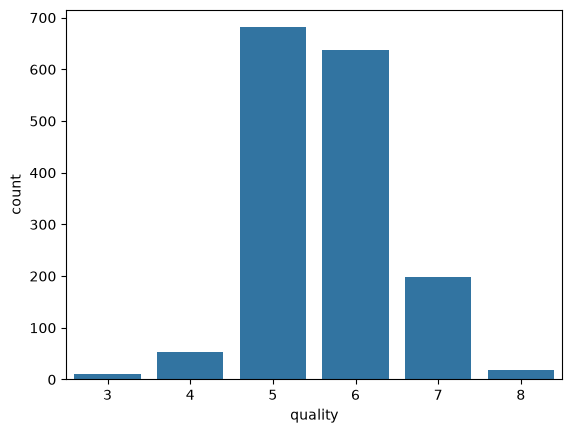

In [59]:
df['quality'].value_counts().sort_index()
sns.countplot(x='quality', data=df)

In [60]:
# as duas variáveis com maiores problemas em relação aos outliers são: free sulfur dioxide e total sulfur dioxide
# não há nenhum vinho caracterizado com nota 10
# variável com menor variação entre os valores de mínimo e o máximo é: density

In [61]:
# Random Forest geralmente se adapta melhor a dados despadronizados em comparação com a regressão logística. 
# Isso ocorre porque o Random Forest é baseado em árvores de decisão, que são menos sensíveis à escala dos dados.

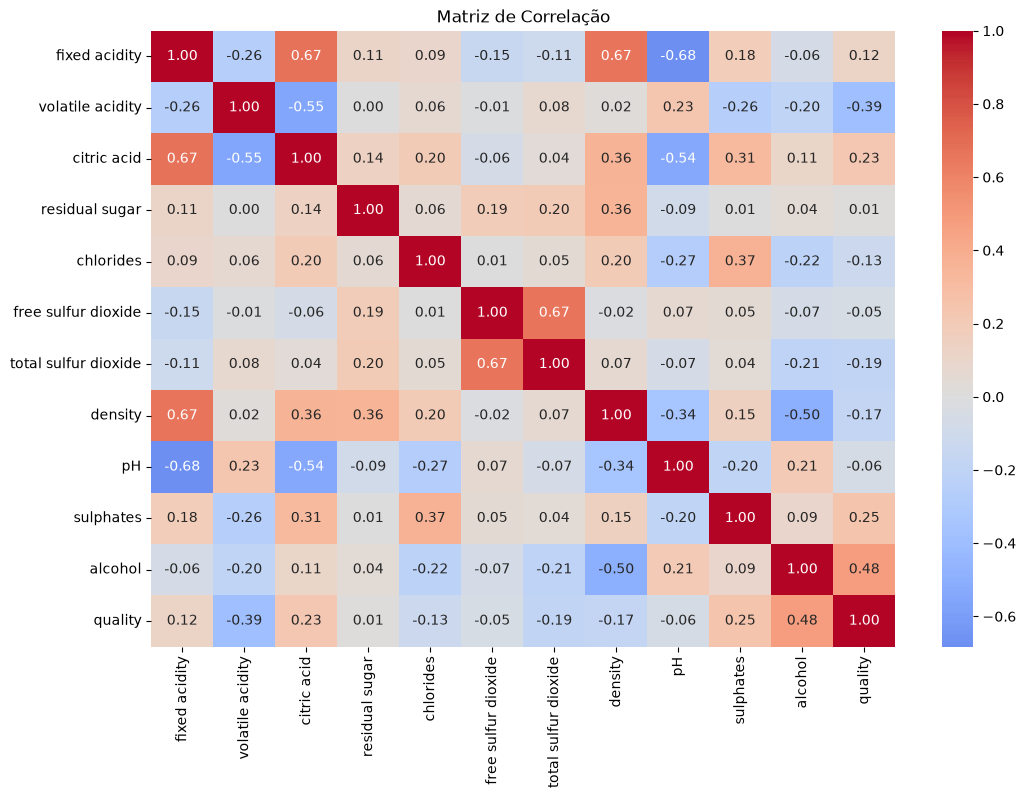

In [62]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de Correlação")
plt.show()

In [63]:
correlacao = df.corr()['quality'].drop('quality').sort_values(key=abs, ascending=False)
correlacao

alcohol                 0.476166
volatile acidity       -0.390558
sulphates               0.251397
citric acid             0.226373
total sulfur dioxide   -0.185100
density                -0.174919
chlorides              -0.128907
fixed acidity           0.124052
pH                     -0.057731
free sulfur dioxide    -0.050656
residual sugar          0.013732
Name: quality, dtype: float64

In [64]:
#Interpretação:

# alcohol (+0.48) é a correlação mais forte: quanto maior o teor alcoólico, maior tende a ser a nota.
# volatile acidity (−0.39) é a correlação negativa mais forte: muita acidez volátil (que dá gosto de vinagre)
# derruba a nota.
# sulphates (+0.25) e citric acid (+0.23) têm uma correlação positiva moderada ou fraca.
# pH, free sulfur dioxide e residual sugar estão perto de zero, então quase não têm relação linear com a qualidade.

In [65]:
df_corr = df[['alcohol', 'volatile acidity', 'sulphates', 'citric acid', 'quality']]
df_corr.head()

,alcohol,volatile acidity,sulphates,citric acid,quality
0,9.4,0.70,0.56,0.00,5
1,9.8,0.88,0.68,0.00,5
2,9.8,0.76,0.65,0.04,5
3,9.8,0.28,0.58,0.56,6
4,9.4,0.70,0.56,0.00,5


# 3 - Preparação Final dos Dados

A) Separe a base em X(Features) e Y(Target)

B) Separe a base em treino e teste.


In [66]:
X = df.drop('quality',axis=1)
y = df['quality']

In [67]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Treino:", X_train.shape)
print("Teste:", X_test.shape)

Treino: (1279, 11)
Teste: (320, 11)


In [68]:
print(y_train.value_counts(normalize=True).sort_index())
print(y_test.value_counts(normalize=True).sort_index())

quality
3    0.006255
4    0.032838
5    0.426114
6    0.398749
7    0.124316
8    0.011728
Name: proportion, dtype: float64
quality
3    0.006250
4    0.034375
5    0.425000
6    0.400000
7    0.125000
8    0.009375
Name: proportion, dtype: float64


# 4 - Modelagem

A) Inicie e treine o modelo de Random Forest

B) Aplique a base de teste o modelo.


In [73]:
modelo = RandomForestClassifier(random_state=42)
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)

In [74]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Acurácia: {accuracy:.2f}")
print("Relatório de Classificação:\n", classification_report(y_test, y_pred, zero_division=0))

Acurácia: 0.68
Relatório de Classificação:
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.71      0.76      0.73       136
           6       0.64      0.71      0.67       128
           7       0.70      0.53      0.60        40
           8       0.50      0.33      0.40         3

    accuracy                           0.68       320
   macro avg       0.43      0.39      0.40       320
weighted avg       0.65      0.68      0.66       320



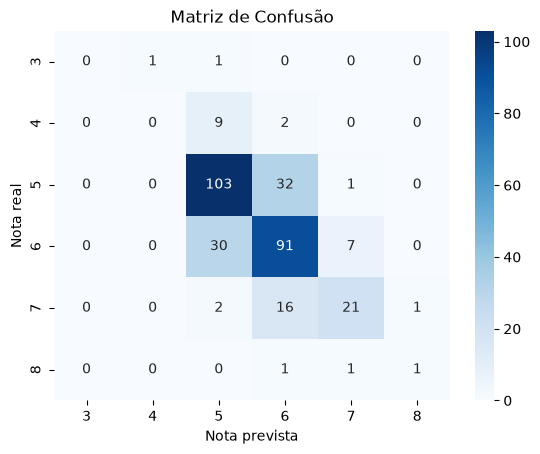

In [75]:
conf_matrix = confusion_matrix(y_test, y_pred)
rotulos = sorted(y.unique())

sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=rotulos, yticklabels=rotulos)
plt.xlabel('Nota prevista')
plt.ylabel('Nota real')
plt.title('Matriz de Confusão')
plt.show()

In [ ]:
# quando o modelo erra, quase sempre erra por uma nota de diferença. Por exemplo, ele confunde 
# muito o 5 com o 6, mas quase nunca prevê 8 para um vinho nota 5. Ou seja, ele erra “perto” do valor certo.

# 5 - Avaliação

A) Avalie as principais métricas da Classificação e traga insights acerca do resultado, interprete os valores achados.

B) Você nota que o modelo teve dificuldade para prever alguma classe? Se sim, acredita que tenha relação com o balanceamento dos dados? Explique.


In [ ]:
# Sim, o modelo teve dificuldade com as notas 3, 4 e 8. As notas 3 e 4 ficaram com recall 0, ou seja, 
# ele nunca acertou nenhuma. Na matriz, os vinhos nota 4 foram quase todos classificados como 5.
# E isso tem relação com o balanceamento, sim. No treino havia só cerca de 8 vinhos nota 3 e 42 nota 4,
# contra mais de 500 de nota 5. Com tão poucos exemplos, o modelo não aprende o padrão dessas classes
# e acaba “puxando” a previsão para as notas mais comuns, porque assim acerta mais no geral. 
# A acurácia alta esconde esse problema, e é por isso que o macro avg e o recall por classe são importantes.

# 6 - Melhorando os Hyperparametros

A) Defina o Grid de parametros que você quer testar

B) Inicie e Treine um novo modelo utilizando o random search.

C) Avalie os resultados do modelo.

D) Você identificou melhorias no modelo após aplicar o random search? Justifique.


ps. Essa parte da atividade demorará um pouco para rodar!

In [77]:
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', None]
}

In [78]:
random_search = RandomizedSearchCV(estimator=modelo, param_distributions=param_grid,
                                   n_iter=100, cv=5, n_jobs=-1, verbose=2, random_state=42, scoring='accuracy')

In [92]:
random_search.fit(X_train, y_train)
print(f"Melhores Hiperparâmetros: {random_search.best_params_}")
print(f"Melhor acurácia na validação cruzada: {random_search.best_score_:.2f}")

Fitting 5 folds for each of 100 candidates, totalling 500 fits
Melhores Hiperparâmetros: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': None, 'max_depth': None}
Melhor acurácia na validação cruzada: 0.68


In [93]:
best_rf_model = random_search.best_estimator_
y_pred_rs = best_rf_model.predict(X_test)

In [94]:
print(f"Acurácia: {accuracy_score(y_test, y_pred_rs):.2f}")
print("Relatório de Classificação:\n", classification_report(y_test, y_pred_rs, zero_division=0))
print("Matriz de Confusão:\n", confusion_matrix(y_test, y_pred_rs))

Acurácia: 0.67
Relatório de Classificação:
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.69      0.76      0.73       136
           6       0.64      0.69      0.66       128
           7       0.73      0.55      0.63        40
           8       0.50      0.33      0.40         3

    accuracy                           0.67       320
   macro avg       0.43      0.39      0.40       320
weighted avg       0.65      0.67      0.66       320

Matriz de Confusão:
 [[  0   1   1   0   0   0]
 [  0   0   8   3   0   0]
 [  0   0 104  31   1   0]
 [  0   0  34  88   6   0]
 [  0   0   3  14  22   1]
 [  0   0   0   1   1   1]]
[CV] END max_depth=10, max_features=log2, min_samples_leaf=4, min_samples_split=10, n_estimators=50; total time=   0.1s
[CV] END max_depth=10, max_features=log2, min_samples_leaf=1, min_samples_split=2, n_estimators=50; total tim

In [ ]:
# não houve melhora relevante. A acurácia ficou praticamente igual, até um pouco abaixo. 
# Os melhores parâmetros encontrados são quase os mesmos do padrão do Random Forest (só o max_features mudou),
# ou seja, o modelo original já estava bem ajustado. Além disso:

# A busca foi otimizada pela acurácia. Essa métrica é dominada pelas notas 5 e 6, 
# então a busca nunca tentou melhorar as classes raras.
# O problema principal é o desbalanceamento, não os hiperparâmetros.
# Nenhuma combinação de parâmetros consegue ensinar o modelo a reconhecer a nota 3 com só cerca 
# de 8 exemplos no treino.
# A diferença de 0,01 é ruído. Com 320 vinhos no teste, isso equivale a 1 ou 2 acertos a mais ou a menos.

# 7 - Chegando a perfeição

Baseado em tudo que você já aprendeu até agora, quais outras técnicas você acredita que poderiam ser aplicadas ao modelo para melhorar ainda mais suas previsões?

In [ ]:
# Técnicas que atacam o desbalanceamento costumam ajudar mais do que ajustar hiperparâmetros:
# class_weight='balanced', oversampling com SMOTE, agrupar as notas em 
# faixas (por exemplo ruim / médio / bom) e usar scoring='f1_macro' na busca.

In [95]:
y_faixas = pd.cut(df['quality'], bins=[0, 4, 6, 10], labels=['ruim', 'medio', 'bom'])

X_train_f, X_test_f, y_train_f, y_test_f = train_test_split(
    X, y_faixas, test_size=0.2, random_state=42, stratify=y_faixas)

modelo_faixas = RandomForestClassifier(random_state=42, class_weight='balanced')
modelo_faixas.fit(X_train_f, y_train_f)
y_pred_f = modelo_faixas.predict(X_test_f)

print(f"Acurácia: {accuracy_score(y_test_f, y_pred_f):.2f}")
print(classification_report(y_test_f, y_pred_f, zero_division=0))

Acurácia: 0.84
              precision    recall  f1-score   support

         bom       0.56      0.74      0.64        43
       medio       0.92      0.89      0.90       264
        ruim       0.43      0.23      0.30        13

    accuracy                           0.84       320
   macro avg       0.64      0.62      0.61       320
weighted avg       0.85      0.84      0.84       320



In [ ]:
# O principal problema do modelo é o desbalanceamento da target: as notas 5 e 6 representam cerca de 82% 
# da base, enquanto as notas 3, 4 e 8 têm pouquíssimos exemplos. Por isso o modelo nunca acertou as notas 3 e 4,
# e o RandomizedSearchCV não trouxe melhora: o problema está nos dados, não nos hiperparâmetros.